# Tugas Praktikum 5: Sequential Pattern Analysis

| | |
|---|---|
| **Nama** | Fauzan Tamma Harish Kunfaza |
| **NRP** | 5054251035 |
| **Algoritma** | PrefixSpan (versi *itemset-aware*, diimplementasikan sendiri dan divalidasi) |

**Tujuan praktikum**
1. Memahami konsep *Sequential Pattern Analysis* dan aplikasinya dalam data mining.
2. Menerapkan algoritma Sequential Pattern Mining (PrefixSpan) pada dataset transaksi.
3. Mengevaluasi pola berurutan yang ditemukan berdasarkan metrik *support* dan *confidence*.

**Alur notebook**
1. Import dataset
2. Eksplorasi dan pembersihan data
3. Persiapan data (sequence per pelanggan)
4. Penerapan algoritma PrefixSpan
5. Evaluasi pola berurutan (support, confidence, tiga pola terbaik)
6. Laporan: hasil, analisis, dan kesimpulan

## 0. Konsep Singkat

Pada *association rule* (Praktikum 4), urutan waktu tidak diperhatikan: keranjang belanja diperlakukan sebagai himpunan. Pada ***sequential pattern mining***, urutan waktu menjadi inti analisis. Pertanyaannya bukan lagi "produk apa yang dibeli bersama?", tetapi **"produk apa yang dibeli setelah produk tertentu?"**

| Istilah | Arti dalam dataset Online Retail |
|---|---|
| **Item** | Satu produk (kolom `Description`) |
| **Itemset** | Kumpulan produk dalam **satu invoice** (satu kali belanja) |
| **Sequence** | Daftar itemset satu pelanggan yang **terurut menurut waktu** (`InvoiceDate`) |
| **Pola berurutan** | Subsequence yang muncul pada banyak pelanggan, mis. `{A} → {B, C}`: pelanggan membeli A, lalu di invoice yang lebih akhir membeli B dan C sekaligus |
| **Support** | Proporsi pelanggan yang sequence-nya memuat pola tersebut: $\text{sup}(P)=\frac{|\{\text{pelanggan yang memuat }P\}|}{N}$ |
| **Confidence** | Untuk pola $P = \langle X,\,Y\rangle$ dengan $Y$ itemset terakhir: $\text{conf}(X \Rightarrow Y)=\frac{\text{sup}(\langle X,Y\rangle)}{\text{sup}(\langle X\rangle)}$, yaitu peluang pelanggan yang sudah menjalani $X$ kemudian membeli $Y$ |
| **Lift** (tambahan) | $\text{conf}(X \Rightarrow Y)\,/\,\text{sup}(\langle Y\rangle)$. Nilai > 1 berarti $Y$ lebih mungkin muncul setelah $X$ dibanding peluang dasarnya |

**PrefixSpan** menghindari pembangkitan kandidat seperti GSP/Apriori. Algoritma ini bekerja dengan *pattern growth* dan *projected database*: pola pendek yang frequent diperpanjang satu item demi satu, dan setiap perpanjangan hanya memeriksa "sisa" (suffix) sequence yang masih relevan. Ada dua jenis perpanjangan:
- **S-extension** (*sequence extension*): item baru dibeli pada invoice yang **lebih akhir**, menjadi itemset baru di belakang pola.
- **I-extension** (*itemset extension*): item baru dibeli **pada invoice yang sama** dengan itemset terakhir pola.

In [5]:
import os
import math
import time
import textwrap
import warnings
from bisect import bisect_right
from collections import defaultdict
from itertools import combinations, product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Unduh dan Import Dataset

Dataset **Online Retail** diunduh dari UCI (<https://archive.ics.uci.edu/dataset/352/online+retail>) dan dibaca dengan `pd.read_excel`. Jika file berada di lokasi lain (mis. Google Drive pada Colab), ubah `DATA_PATH`. Proses membaca file Excel berukuran ±23 MB membutuhkan waktu sekitar setengah menit.

In [6]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
# Lokasi file dataset. Sesuaikan jika berbeda (mis. "/content/drive/MyDrive/Online Retail.xlsx")
CANDIDATES = ["Online Retail.xlsx", "Online_Retail.xlsx"]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), CANDIDATES[0])
print("Membaca file:", DATA_PATH)

df_raw = pd.read_excel(DATA_PATH)

Membaca file: Online Retail.xlsx


In [8]:
# Lima baris pertama
df_raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
# Dimensi dataset
print("Shape (baris, kolom):", df_raw.shape)

Shape (baris, kolom): (541909, 8)


In [10]:
# Struktur kolom, tipe data, dan jumlah nilai non-null
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


**Atribut dataset**

| Kolom | Keterangan |
|---|---|
| `InvoiceNo` | Nomor invoice (6 digit). Diawali huruf **C** berarti transaksi dibatalkan |
| `StockCode` | Kode produk |
| `Description` | Nama produk |
| `Quantity` | Jumlah produk per transaksi |
| `InvoiceDate` | Tanggal dan waktu transaksi |
| `UnitPrice` | Harga satuan (GBP) |
| `CustomerID` | ID pelanggan (6 digit) |
| `Country` | Negara pelanggan |

Dari `.info()` terlihat bahwa `Description` dan `CustomerID` memiliki nilai kosong. Kedua kolom ini penting untuk analisis, sehingga perlu ditangani pada tahap pembersihan.

## 2. Eksplorasi dan Pembersihan Data

### 2.1 Kolom yang relevan

Untuk membentuk sequence pembelian per pelanggan, kolom yang dipakai adalah:

| Kolom | Peran dalam analisis |
|---|---|
| `CustomerID` | Penentu **sequence**: satu pelanggan = satu sequence |
| `InvoiceDate` | Penentu **urutan waktu** antar-invoice |
| `InvoiceNo` | Penentu **itemset**: semua item dengan `InvoiceNo` yang sama menjadi satu itemset |
| `Description` | **Item** (nama produk) |
| `Quantity` | Dipakai hanya untuk menyaring baris yang tidak valid |

Kolom `StockCode`, `UnitPrice`, dan `Country` tidak dipakai untuk membentuk sequence (`StockCode` hanya dipakai pada satu langkah pembersihan tambahan).

### 2.2 Eksplorasi kualitas data

In [11]:
# Nilai kosong per kolom
missing = df_raw.isna().sum().to_frame("jumlah_kosong")
missing["persen"] = (missing["jumlah_kosong"] / len(df_raw) * 100).round(2)
display(missing)

# Baris yang akan dibuang pada tahap pembersihan
n_cancel = df_raw["InvoiceNo"].astype(str).str.startswith("C").sum()
n_qty = (df_raw["Quantity"] <= 0).sum()
print(f"Baris transaksi dibatalkan (InvoiceNo diawali 'C') : {n_cancel:,}")
print(f"Baris dengan Quantity <= 0                         : {n_qty:,}")

,jumlah_kosong,persen
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Baris transaksi dibatalkan (InvoiceNo diawali 'C') : 9,288
Baris dengan Quantity <= 0                         : 10,624


### 2.3 Pembersihan data

Pembersihan dilakukan bertahap sesuai ketentuan tugas, dan **jumlah baris, invoice, serta pelanggan dicatat setelah setiap tahap** agar dampak tiap langkah terlihat. (Catatan: `nunique()` mengabaikan nilai kosong, sehingga jumlah pelanggan pada data awal hanya menghitung baris yang `CustomerID`-nya terisi.)

Urutan langkah:
1. Hapus baris dengan `Description` kosong.
2. Hapus transaksi dibatalkan (`InvoiceNo` diawali huruf "C").
3. Hapus baris dengan `Quantity` negatif atau nol.
4. Hapus baris dengan `CustomerID` kosong (sequence disusun per pelanggan).
5. *(Tambahan, di luar ketentuan)* Rapikan penulisan `Description`, lalu buang baris biaya non-produk. Alasan dijelaskan di bawah.

In [12]:
def ringkas(d, tahap):
    return {
        "Tahap": tahap,
        "Jumlah baris": len(d),
        "Jumlah invoice": d["InvoiceNo"].nunique(),
        "Jumlah pelanggan": d["CustomerID"].nunique(),
    }

log = [ringkas(df_raw, "0. Data awal (sebelum pembersihan)")]

df = df_raw.copy()

# 1. Description kosong
df = df[df["Description"].notna()]
log.append(ringkas(df, "1. Hapus Description kosong"))

# 2. Transaksi dibatalkan (InvoiceNo diawali 'C')
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
log.append(ringkas(df, "2. Hapus transaksi dibatalkan (InvoiceNo diawali 'C')"))

# 3. Quantity negatif atau nol
df = df[df["Quantity"] > 0]
log.append(ringkas(df, "3. Hapus Quantity <= 0"))

# 4. CustomerID kosong
df = df[df["CustomerID"].notna()].copy()
df["CustomerID"] = df["CustomerID"].astype(int)
log.append(ringkas(df, "4. Hapus CustomerID kosong  (= hasil pembersihan sesuai ketentuan)"))

df_bersih_wajib = df.copy()   # simpan untuk perbandingan

**Langkah tambahan (5): biaya non-produk.** Beberapa baris pada dataset bukan produk yang dibeli, melainkan biaya layanan. Jika dibiarkan, baris tersebut akan tampil sebagai "produk" paling sering dan menghasilkan pola yang menyesatkan secara bisnis (misalnya `POSTAGE → POSTAGE`). Berikut baris yang `StockCode`-nya bukan kode produk:

In [13]:
kode_huruf = df[df["StockCode"].astype(str).str.fullmatch(r"[A-Za-z]+")]
display(kode_huruf.groupby(["StockCode", "Description"]).size().rename("jumlah_baris").to_frame())

,,jumlah_baris
StockCode,Description,
DOT,DOTCOM POSTAGE,16
M,Manual,290
PADS,PADS TO MATCH ALL CUSHIONS,4
POST,POSTAGE,1099


In [14]:
# Rapikan teks Description: huruf kapital, spasi ganda dihapus (mis. "LUNCH BAG  BLACK SKULL." -> satu spasi)
n_sebelum = df["Description"].nunique()
df["Description"] = (df["Description"].str.upper()
                                       .str.replace(r"\s+", " ", regex=True)
                                       .str.strip())
print(f"Jumlah Description unik: {n_sebelum:,} -> {df['Description'].nunique():,} setelah dirapikan")

# Buang biaya non-produk: POST (POSTAGE), M (MANUAL), DOT (DOTCOM POSTAGE)
NON_PRODUK = ["POST", "M", "DOT"]
df = df[~df["StockCode"].astype(str).isin(NON_PRODUK)].copy()
log.append(ringkas(df, "5. (Tambahan) Hapus biaya non-produk POST / M / DOT"))

tabel_bersih = pd.DataFrame(log)
tabel_bersih

Jumlah Description unik: 3,877 -> 3,858 setelah dirapikan


,Tahap,Jumlah baris,Jumlah invoice,Jumlah pelanggan
0,0. Data awal (sebelum pembersihan),541909,25900,4372
1,1. Hapus Description kosong,540455,24446,4372
2,2. Hapus transaksi dibatalkan (InvoiceNo diawali 'C'),531167,20610,4339
3,3. Hapus Quantity <= 0,530693,20136,4339
4,4. Hapus CustomerID kosong (= hasil pembersihan sesuai ketentuan),397924,18536,4339
5,5. (Tambahan) Hapus biaya non-produk POST / M / DOT,396519,18419,4336


In [15]:
awal, wajib, akhir = log[0], log[4], log[5]
print("RINGKASAN SEBELUM vs SESUDAH PEMBERSIHAN")
print("-" * 62)
print(f"{'':28s}{'Baris':>10s}{'Invoice':>10s}{'Pelanggan':>12s}")
for nama, r in [("Sebelum pembersihan", awal),
                ("Sesudah (sesuai ketentuan)", wajib),
                ("Sesudah (+ langkah tambahan)", akhir)]:
    print(f"{nama:28s}{r['Jumlah baris']:>10,}{r['Jumlah invoice']:>10,}{r['Jumlah pelanggan']:>12,}")
print("-" * 62)
print(f"Baris yang dibuang (total): {awal['Jumlah baris'] - akhir['Jumlah baris']:,} "
      f"({(1 - akhir['Jumlah baris'] / awal['Jumlah baris']) * 100:.1f}% dari data awal)")

RINGKASAN SEBELUM vs SESUDAH PEMBERSIHAN
--------------------------------------------------------------
                                 Baris   Invoice   Pelanggan
Sebelum pembersihan            541,909    25,900       4,372
Sesudah (sesuai ketentuan)     397,924    18,536       4,339
Sesudah (+ langkah tambahan)   396,519    18,419       4,336
--------------------------------------------------------------
Baris yang dibuang (total): 145,390 (26.8% dari data awal)


### 2.4 Eksplorasi singkat data bersih

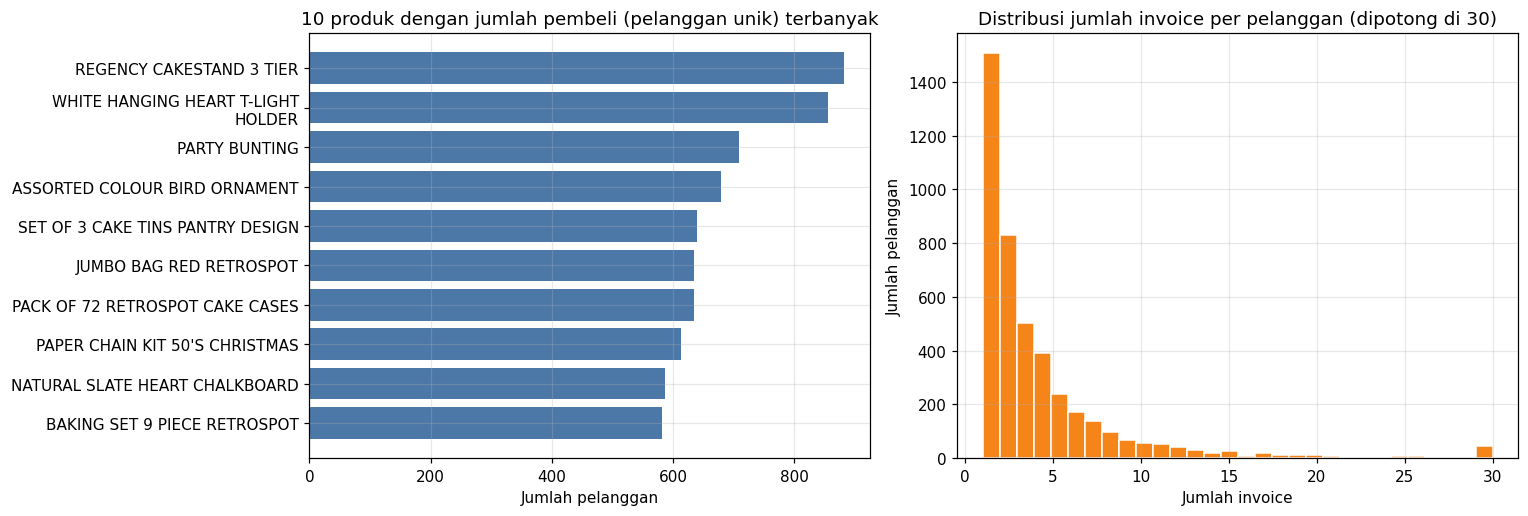

Statistik jumlah invoice per pelanggan:
count    4336.00
mean        4.25
std         7.65
min         1.00
25%         1.00
50%         2.00
75%         5.00
max       206.00

Pelanggan dengan hanya 1 invoice: 1,506 (34.7%)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# (a) 10 produk yang dibeli oleh pelanggan terbanyak
top10 = df.groupby("Description")["CustomerID"].nunique().nlargest(10).iloc[::-1]
axes[0].barh([textwrap.fill(t, 32) for t in top10.index], top10.values, color="#4C78A8")
axes[0].set_title("10 produk dengan jumlah pembeli (pelanggan unik) terbanyak")
axes[0].set_xlabel("Jumlah pelanggan")

# (b) Distribusi jumlah invoice per pelanggan
inv_per_cust = df.groupby("CustomerID")["InvoiceNo"].nunique()
axes[1].hist(inv_per_cust.clip(upper=30), bins=30, color="#F58518", edgecolor="white")
axes[1].set_title("Distribusi jumlah invoice per pelanggan (dipotong di 30)")
axes[1].set_xlabel("Jumlah invoice")
axes[1].set_ylabel("Jumlah pelanggan")

plt.tight_layout()
plt.show()

print("Statistik jumlah invoice per pelanggan:")
print(inv_per_cust.describe().round(2).to_string())
print(f"\nPelanggan dengan hanya 1 invoice: {(inv_per_cust == 1).sum():,} ({(inv_per_cust == 1).mean():.1%})")

**Catatan eksplorasi.** Sebagian besar pelanggan hanya memiliki sedikit invoice, dan banyak yang hanya satu. Pelanggan dengan satu invoice hanya menghasilkan sequence satu itemset, sehingga tidak dapat menyumbang pola berurutan (urutan butuh minimal dua kali belanja). Pelanggan seperti ini tetap dipertahankan, karena support dihitung **relatif terhadap seluruh pelanggan** sesuai ketentuan tugas.

## 3. Persiapan Data untuk Sequential Pattern Mining

Tiga langkah:
1. Urutkan data berdasarkan `CustomerID` dan `InvoiceDate` (jika waktu sama, dipecah dengan `InvoiceNo`).
2. Kelompokkan item pada satu invoice menjadi **satu itemset** (produk yang sama pada satu invoice dihitung sekali).
3. Susun tiap pelanggan menjadi **satu sequence**: daftar itemset yang urut secara waktu, disimpan sebagai *list of list* (`[[item, ...], [item, ...], ...]`).

In [17]:
# 1. Urutkan berdasarkan CustomerID dan InvoiceDate
df = df.sort_values(["CustomerID", "InvoiceDate", "InvoiceNo"]).reset_index(drop=True)

# 2. Satu invoice = satu itemset (kumpulan Description unik pada invoice tersebut)
invoice_df = (df.groupby(["CustomerID", "InvoiceNo"])
                .agg(InvoiceDate=("InvoiceDate", "min"),
                     itemset=("Description", lambda s: sorted(set(s))))
                .reset_index()
                .sort_values(["CustomerID", "InvoiceDate", "InvoiceNo"])
                .reset_index(drop=True))
invoice_df["jumlah_item"] = invoice_df["itemset"].str.len()

# Tampilan ringkas: hanya 3 item pertama tiap itemset
tampil = invoice_df.assign(contoh_itemset=invoice_df["itemset"].map(lambda l: l[:3] + (["..."] if len(l) > 3 else [])))
tampil[["CustomerID", "InvoiceNo", "InvoiceDate", "jumlah_item", "contoh_itemset"]].head(8)

,CustomerID,InvoiceNo,InvoiceDate,jumlah_item,contoh_itemset
0,12346,541431,2011-01-18 10:01:00,1,[MEDIUM CERAMIC TOP STORAGE JAR]
1,12347,537626,2010-12-07 14:57:00,31,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, ALARM CLOCK BAKELIKE CHOCOLATE, ...]"
2,12347,542237,2011-01-26 14:30:00,29,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIRY CAKE CASES, 72 SWEETHEART FAIRY CAKE CASES, ...]"
3,12347,549222,2011-04-07 10:43:00,24,"[3D SHEET OF CAT STICKERS, 3D SHEET OF DOG STICKERS, AIRLINE BAG VINTAGE JET SET BROWN, ...]"
4,12347,556201,2011-06-09 13:01:00,18,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE TOKYO 78, ...]"
5,12347,562032,2011-08-02 08:48:00,22,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIRY CAKE CASES, 72 SWEETHEART FAIRY CAKE CASES, ...]"
6,12347,573511,2011-10-31 12:25:00,47,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIRY CAKE CASES, 72 SWEETHEART FAIRY CAKE CASES, ...]"
7,12347,581180,2011-12-07 15:52:00,11,"[BICYCLE PUNCTURE REPAIR KIT, BOOM BOX SPEAKER BOYS, CHRISTMAS TABLE SILVER CANDLE SPIKE, ...]"


In [18]:
# 3. Satu pelanggan = satu sequence (list of list)
seq_per_customer = invoice_df.groupby("CustomerID")["itemset"].apply(list)
customer_ids = seq_per_customer.index.to_list()
sequences = seq_per_customer.to_list()          # list of list of list (nama produk)

N = len(sequences)
print(f"Jumlah sequence (pelanggan) : {N:,}")
print(f"Jumlah itemset (invoice)    : {sum(len(s) for s in sequences):,}")
print(f"Jumlah item unik (produk)   : {len({i for s in sequences for el in s for i in el}):,}")

# Contoh sequence pelanggan pertama yang memiliki 3 invoice atau lebih
contoh = next(i for i, s in enumerate(sequences) if len(s) >= 3)
print(f"\nContoh sequence pelanggan {customer_ids[contoh]} ({len(sequences[contoh])} itemset), 3 itemset pertama:")
for k, el in enumerate(sequences[contoh][:3], start=1):
    tampil = ", ".join(el[:4]) + (f", ... (+{len(el) - 4} item)" if len(el) > 4 else "")
    print(f"  itemset {k}: [{tampil}]")

Jumlah sequence (pelanggan) : 4,336
Jumlah itemset (invoice)    : 18,419
Jumlah item unik (produk)   : 3,855

Contoh sequence pelanggan 12347 (7 itemset), 3 itemset pertama:
  itemset 1: [3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, ALARM CLOCK BAKELIKE CHOCOLATE, ALARM CLOCK BAKELIKE GREEN, ... (+27 item)]
  itemset 2: [3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIRY CAKE CASES, 72 SWEETHEART FAIRY CAKE CASES, AIRLINE BAG VINTAGE JET SET BROWN, ... (+25 item)]
  itemset 3: [3D SHEET OF CAT STICKERS, 3D SHEET OF DOG STICKERS, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE JET SET RED, ... (+20 item)]


In [19]:
# Statistik panjang sequence (jumlah itemset per pelanggan)
panjang = pd.Series([len(s) for s in sequences], name="jumlah_itemset")
print(panjang.describe().round(2).to_string())

# Pelanggan dengan >= 2 itemset: hanya mereka yang dapat membentuk pola berurutan
print(f"\nPelanggan dengan >= 2 invoice: {(panjang >= 2).sum():,} ({(panjang >= 2).mean():.1%})")

count    4336.00
mean        4.25
std         7.65
min         1.00
25%         1.00
50%         2.00
75%         5.00
max       206.00

Pelanggan dengan >= 2 invoice: 2,830 (65.3%)


In [20]:
# Encoding item -> bilangan bulat agar pencarian pola lebih cepat.
# Setiap itemset disimpan sebagai tuple terurut; sequence = list of tuple.
vocab = sorted({i for s in sequences for el in s for i in el})
item2id = {name: k for k, name in enumerate(vocab)}
id2item = {k: name for name, k in item2id.items()}

sequences_id = [[tuple(sorted(item2id[i] for i in el)) for el in s] for s in sequences]
print(f"Jumlah item unik: {len(vocab):,}")
print(f"Contoh hasil encoding (pelanggan {customer_ids[contoh]}, 2 itemset pertama, 6 item pertama tiap itemset):")
print([el[:6] for el in sequences_id[contoh][:2]])
print("Arti id:", {k: id2item[k] for k in sequences_id[contoh][0][:3]})

Jumlah item unik: 3,855
Contoh hasil encoding (pelanggan 12347, 2 itemset pertama, 6 item pertama tiap itemset):
[(58, 126, 132, 133, 135, 136), (58, 99, 103, 126, 128, 132)]
Arti id: {58: '3D DOG PICTURE PLAYING CARDS', 126: 'AIRLINE BAG VINTAGE JET SET BROWN', 132: 'ALARM CLOCK BAKELIKE CHOCOLATE'}


## 4. Penerapan Algoritma: PrefixSpan

### 4.1 Implementasi

Pustaka `prefixspan` yang dipakai pada materi (5.4.1) bekerja pada urutan **item tunggal**, sehingga tidak dapat membedakan dua produk yang dibeli pada invoice yang sama dengan dua produk yang dibeli pada invoice berbeda. Karena ketentuan tugas meminta item satu invoice dijadikan **satu itemset**, PrefixSpan di sini diimplementasikan dalam versi *itemset-aware*. Prinsip kerjanya sama dengan PrefixSpan asli (Pei dkk., 2001):

1. Hitung support tiap item (jumlah **pelanggan** yang memuatnya), buang item yang tidak memenuhi minimum support.
2. Mulai dari pola kosong dengan *projected database* berisi seluruh sequence.
3. Pada setiap pola, periksa suffix tiap sequence untuk mencari item yang dapat memperpanjang pola:
   - **S-extension**: item muncul pada itemset yang lebih akhir (invoice berikutnya),
   - **I-extension**: item muncul pada itemset yang sama dengan item terakhir pola (invoice yang sama, urutan leksikografis).
4. Item yang support-nya memenuhi minimum diterima sebagai pola baru, lalu diproses secara rekursif dengan projected database yang lebih kecil.

Support dihitung **per pelanggan** (satu pelanggan dihitung satu kali walau polanya muncul berkali-kali).

In [21]:
def prefixspan(sequences, min_count, max_items=None):
    # PrefixSpan untuk database sequence of itemsets.
    #   sequences : list of sequence; sequence = list of itemset; itemset = tuple item terurut
    #   min_count : minimum support dalam jumlah sequence (pelanggan)
    #   max_items : (opsional) batas total item dalam satu pola
    # Return: dict {pola: support_count}; pola = tuple of itemset (tuple of item)
    # 1) Support tiap item, lalu buang item yang tidak frequent
    count = defaultdict(int)
    for seq in sequences:
        for x in {x for el in seq for x in el}:
            count[x] += 1
    frequent = {x for x, c in count.items() if c >= min_count}

    db, db_sets = [], []
    for seq in sequences:
        kept = [tuple(x for x in el if x in frequent) for el in seq]
        kept = [el for el in kept if el]
        db.append(kept)
        db_sets.append([frozenset(el) for el in kept])

    patterns = {}

    def grow(prefix, projected, n_items):
        # prefix    : pola saat ini (list of tuple)
        # projected : list (id_sequence, posisi itemset tempat itemset terakhir pola selesai
        #             dipasangkan pada embedding paling awal)
        last = prefix[-1] if prefix else ()
        last_set, last_max = frozenset(last), (last[-1] if last else None)
        s_cand, i_cand = defaultdict(list), defaultdict(list)

        for sid, pos in projected:
            seq, sets = db[sid], db_sets[sid]

            # S-extension: item pada itemset setelah posisi pos (munculan paling awal)
            first = {}
            for k in range(pos + 1, len(seq)):
                for x in seq[k]:
                    if x not in first:
                        first[x] = k
            for x, k in first.items():
                s_cand[x].append((sid, k))

            # I-extension: itemset (pos atau sesudahnya) yang memuat seluruh itemset terakhir pola;
            # item baru harus lebih besar dari item terakhir agar tiap pola dibangkitkan sekali saja
            if last:
                first = {}
                for k in range(pos, len(seq)):
                    if last_set <= sets[k]:
                        el = seq[k]
                        for x in el[bisect_right(el, last_max):]:
                            if x not in first:
                                first[x] = k
                for x, k in first.items():
                    i_cand[x].append((sid, k))

        # perpanjang pada itemset terakhir (I-extension), lalu tambah itemset baru (S-extension)
        for x, proj in i_cand.items():
            if len(proj) >= min_count:
                new_prefix = prefix[:-1] + [last + (x,)]
                patterns[tuple(new_prefix)] = len(proj)
                if max_items is None or n_items + 1 < max_items:
                    grow(new_prefix, proj, n_items + 1)
        for x, proj in s_cand.items():
            if len(proj) >= min_count:
                new_prefix = prefix + [(x,)]
                patterns[tuple(new_prefix)] = len(proj)
                if max_items is None or n_items + 1 < max_items:
                    grow(new_prefix, proj, n_items + 1)

    grow([], [(sid, -1) for sid in range(len(db))], 0)
    return patterns

### 4.2 Validasi implementasi

Sebelum dipakai pada data sebenarnya, implementasi diuji pada contoh kecil klasik dari paper PrefixSpan (4 sequence, `min_count = 2`) dan hasilnya dibandingkan dengan **pencacahan brute force** (membangkitkan semua kemungkinan subsequence lalu menghitung supportnya satu per satu). Jika implementasi benar, kedua metode harus menghasilkan himpunan pola dan support yang identik.

In [22]:
def contains(seq, pattern):
    # True jika pattern adalah subsequence dari seq (setiap itemset pola harus subset dari suatu itemset seq, berurutan)
    k = 0
    for el in pattern:
        while k < len(seq) and not set(el) <= set(seq[k]):
            k += 1
        if k == len(seq):
            return False
        k += 1
    return True

def brute_force(seqs, min_count):
    candidates = set()
    for seq in seqs:
        options = []
        for el in seq:
            subsets = [c for r in range(1, len(el) + 1) for c in combinations(el, r)]
            options.append([None] + subsets)           # itemset boleh dilewati atau diambil sebagian
        for choice in product(*options):
            pat = tuple(c for c in choice if c is not None)
            if pat:
                candidates.add(pat)
    result = {}
    for pat in candidates:
        sup = sum(contains(s, pat) for s in seqs)
        if sup >= min_count:
            result[pat] = sup
    return result

# Contoh dari paper PrefixSpan: <a(abc)(ac)d(cf)>, <(ad)c(bc)(ae)>, <(ef)(ab)(df)cb>, <eg(af)cbc>
toy = [
    [("a",), ("a", "b", "c"), ("a", "c"), ("d",), ("c", "f")],
    [("a", "d"), ("c",), ("b", "c"), ("a", "e")],
    [("e", "f"), ("a", "b"), ("d", "f"), ("c",), ("b",)],
    [("e",), ("g",), ("a", "f"), ("c",), ("b",), ("c",)],
]
hasil_ps = prefixspan(toy, min_count=2)
hasil_bf = brute_force(toy, min_count=2)

print(f"Jumlah pola PrefixSpan  : {len(hasil_ps)}")
print(f"Jumlah pola brute force : {len(hasil_bf)}")
print("Himpunan pola dan support identik:", hasil_ps == hasil_bf)
assert hasil_ps == hasil_bf

def tulis(pat):
    return " → ".join("{" + ",".join(el) + "}" if len(el) > 1 else el[0] for el in pat)

# Pola I-extension (item pada invoice yang sama) harus ikut ditemukan
for pat in [(("a", "b"),), (("a",), ("b", "c"))]:
    print(f"Pola {tulis(pat)} ditemukan: {pat in hasil_ps}  (support = {hasil_ps.get(pat)})")
    assert pat in hasil_ps

print("\nContoh beberapa pola dengan support tertinggi (a → b berarti a dibeli lebih dulu, {a,b} berarti satu invoice):")
for pat, sup in sorted(hasil_ps.items(), key=lambda kv: (-kv[1], len(kv[0]), kv[0]))[:6]:
    print(f"  {tulis(pat):12s} support = {sup}")

Jumlah pola PrefixSpan  : 53
Jumlah pola brute force : 53
Himpunan pola dan support identik: True
Pola {a,b} ditemukan: True  (support = 2)
Pola a → {b,c} ditemukan: True  (support = 2)

Contoh beberapa pola dengan support tertinggi (a → b berarti a dibeli lebih dulu, {a,b} berarti satu invoice):
  a            support = 4
  b            support = 4
  c            support = 4
  a → b        support = 4
  a → c        support = 4
  d            support = 3


Kedua metode menghasilkan pola dan support yang identik, termasuk pola I-extension seperti `{a,b}` dan `a → {b,c}`, sehingga implementasi dapat dipercaya untuk data sebenarnya.

### 4.3 Menentukan minimum support

Ketentuan tugas meminta `min_support = 0.01` (relatif terhadap jumlah pelanggan) sebagai titik awal, lalu menyesuaikannya jika pola terlalu sedikit atau terlalu banyak. Berikut percobaan beberapa nilai. Pola dengan **minimal 2 itemset** (melibatkan sekurang-kurangnya dua invoice berbeda) disebut *pola berurutan*; pola dengan satu itemset hanyalah itemset yang sering muncul, bukan urutan.

In [23]:
experiments = [
    # (min_support, batas panjang pola dalam jumlah item)
    (0.01, 2),      # titik awal sesuai ketentuan; dibatasi 2 item agar selesai dalam waktu wajar
    (0.02, None),
    (0.03, None),
    (0.05, None),
]

rows = []
for ms, cap in experiments:
    min_count = math.ceil(ms * N)
    t0 = time.time()
    pats = prefixspan(sequences_id, min_count, max_items=cap)
    dt = time.time() - t0
    rows.append({
        "min_support": ms,
        "min_count (pelanggan)": min_count,
        "batas panjang pola": "maks. 2 item" if cap else "tanpa batas",
        "total pola": len(pats),
        "pola berurutan (>= 2 itemset)": sum(len(p) >= 2 for p in pats),
        "waktu (detik)": round(dt, 1),
    })
    print(f"min_support={ms:<5} selesai: {len(pats):,} pola dalam {dt:.1f} detik")

eksperimen = pd.DataFrame(rows)
eksperimen

min_support=0.01  selesai: 22,814 pola dalam 12.6 detik
min_support=0.02  selesai: 5,329 pola dalam 32.8 detik
min_support=0.03  selesai: 1,277 pola dalam 9.1 detik
min_support=0.05  selesai: 308 pola dalam 1.5 detik


,min_support,min_count (pelanggan),batas panjang pola,total pola,pola berurutan (>= 2 itemset),waktu (detik)
0,0.01,44,maks. 2 item,22814,15686,12.6
1,0.02,87,tanpa batas,5329,3121,32.8
2,0.03,131,tanpa batas,1277,345,9.1
3,0.05,217,tanpa batas,308,10,1.5


**Pembahasan dan keputusan.** Jumlah pelanggan (N) = 4.336, sehingga `min_support = 0.01` setara dengan minimal 44 pelanggan.

| min_support | Temuan | Penilaian |
|---|---|---|
| **0.01** (titik awal) | Bahkan setelah panjang pola dibatasi 2 item, dihasilkan **22.814 pola** (15.686 di antaranya berurutan). Pada uji coba terpisah dengan batas 3 item, jumlahnya naik menjadi sekitar **59 ribu pola** dengan waktu proses lebih dari 2,5 menit; tanpa batas panjang, proses akan jauh lebih berat lagi. | **Terlalu banyak**: tidak mungkin dievaluasi satu per satu, dan sebagian besar hanyalah variasi kombinasi produk yang sama |
| 0.02 | 5.329 pola (3.121 berurutan), ±36 detik | Masih terlalu banyak untuk ditelaah, memuat banyak pola redundan |
| **0.03** | **1.277 pola, 345 di antaranya berurutan**, ±9 detik | **Dipilih**: jumlahnya cukup untuk dianalisis, dan memuat pola pembelian ulang maupun pola lintas produk |
| 0.05 | Hanya 308 pola, **10** berurutan, dan kesepuluhnya hanyalah pembelian ulang produk yang sama | **Terlalu sedikit**: pola lintas produk sama sekali tidak tertangkap |

Berdasarkan percobaan tersebut, **`min_support = 0.03`** (minimal 131 dari 4.336 pelanggan) dipakai untuk analisis selanjutnya. Alasannya: pada nilai 0.01 hasil terlalu banyak dan tidak praktis, sedangkan pada 0.05 hasil terlalu sedikit dan tidak informatif. Nilai 0.03 berada di titik tengah yang menghasilkan pola yang cukup banyak untuk dibandingkan, namun tetap dapat diinterpretasikan.

In [24]:
MIN_SUPPORT = 0.03
MIN_COUNT = math.ceil(MIN_SUPPORT * N)
print(f"min_support = {MIN_SUPPORT}  ->  minimal {MIN_COUNT} dari {N:,} pelanggan")

t0 = time.time()
patterns = prefixspan(sequences_id, MIN_COUNT)          # dict {pola: support_count}
print(f"PrefixSpan selesai dalam {time.time() - t0:.1f} detik")
print(f"Total pola frequent (semua panjang)         : {len(patterns):,}")
print(f"  - pola 1 itemset (bukan urutan)           : {sum(len(p) == 1 for p in patterns):,}")
print(f"  - pola berurutan (>= 2 itemset)           : {sum(len(p) >= 2 for p in patterns):,}")

min_support = 0.03  ->  minimal 131 dari 4,336 pelanggan
PrefixSpan selesai dalam 7.6 detik
Total pola frequent (semua panjang)         : 1,277
  - pola 1 itemset (bukan urutan)           : 932
  - pola berurutan (>= 2 itemset)           : 345


## 5. Evaluasi Pola Berurutan

### 5.1 Menghitung support dan confidence

Setiap pola berurutan $P=\langle s_1, s_2, \dots, s_n\rangle$ ($n \ge 2$) dibaca sebagai aturan **antecedent ⇒ consequent**, dengan antecedent $=\langle s_1,\dots,s_{n-1}\rangle$ dan consequent $= s_n$ (itemset terakhir):

$$\text{support}(P)=\frac{\#\text{pelanggan yang memuat }P}{N},\qquad
\text{confidence}=\frac{\text{support}(P)}{\text{support}(\text{antecedent})},\qquad
\text{lift}=\frac{\text{confidence}}{\text{support}(s_n)}$$

Karena subsequence dari pola frequent pasti frequent (sifat anti-monotone), support antecedent dan consequent selalu sudah tersedia dari hasil PrefixSpan.

In [25]:
def fmt_itemset(el):
    return id2item[el[0]] if len(el) == 1 else "{" + ", ".join(id2item[i] for i in el) + "}"

def fmt_pattern(p):
    return " → ".join(fmt_itemset(el) for el in p)

rows = []
for p, cnt in patterns.items():
    if len(p) < 2:                       # hanya pola berurutan
        continue
    antecedent, consequent = p[:-1], p[-1]
    cnt_ante = patterns[antecedent]
    cnt_cons = patterns[(consequent,)]
    confidence = cnt / cnt_ante
    rows.append({
        "Pola Berurutan": fmt_pattern(p),
        "Antecedent": fmt_pattern(antecedent),
        "Consequent": fmt_itemset(consequent),
        "Jumlah Itemset": len(p),
        "Jumlah Item": sum(len(el) for el in p),
        "Support Count": cnt,
        "Support": cnt / N,
        "Count Antecedent": cnt_ante,
        "Confidence": confidence,
        "Lift": confidence / (cnt_cons / N),
        "Pembelian Ulang": len({i for el in p for i in el}) == 1,   # pola hanya melibatkan satu produk
    })

hasil = (pd.DataFrame(rows)
           .sort_values(["Support", "Confidence"], ascending=False)
           .reset_index(drop=True))
hasil.index = hasil.index + 1
hasil.index.name = "Peringkat"

print(f"Jumlah pola berurutan: {len(hasil):,}")
print("\nBanyak pola menurut jumlah itemset (invoice) yang terlibat:")
print(hasil["Jumlah Itemset"].value_counts().sort_index().to_string())
print(f"\nPola pembelian ulang satu produk : {hasil['Pembelian Ulang'].sum():,}")
print(f"Pola lintas produk              : {(~hasil['Pembelian Ulang']).sum():,}")

Jumlah pola berurutan: 345

Banyak pola menurut jumlah itemset (invoice) yang terlibat:
Jumlah Itemset
2    334
3     10
4      1

Pola pembelian ulang satu produk : 66
Pola lintas produk              : 279


In [26]:
# 30 pola berurutan dengan support tertinggi
kolom = ["Pola Berurutan", "Support Count", "Support", "Confidence", "Lift"]
hasil[kolom].head(30).round({"Support": 4, "Confidence": 4, "Lift": 2})

,Pola Berurutan,Support Count,Support,Confidence,Lift
Peringkat,,,,,
1,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,405,0.0934,0.4731,2.40
2,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,330,0.0761,0.3746,1.84
3,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,312,0.0720,0.4913,3.36
4,ASSORTED COLOUR BIRD ORNAMENT → ASSORTED COLOUR BIRD ORNAMENT,291,0.0671,0.4292,2.74
5,PARTY BUNTING → PARTY BUNTING,280,0.0646,0.3955,2.42
6,LUNCH BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,276,0.0637,0.5188,4.23
7,LUNCH BAG BLACK SKULL. → LUNCH BAG BLACK SKULL.,229,0.0528,0.5000,4.73
8,LUNCH BAG SUKI DESIGN → LUNCH BAG SUKI DESIGN,226,0.0521,0.5207,5.20
9,SET OF 3 CAKE TINS PANTRY DESIGN → SET OF 3 CAKE TINS PANTRY DESIGN,225,0.0519,0.3516,2.38


### 5.2 Tiga pola terbaik berdasarkan support tertinggi

In [27]:
top3 = hasil.head(3)
display(top3[["Pola Berurutan", "Support Count", "Support", "Confidence", "Lift"]].round({"Support": 4, "Confidence": 4, "Lift": 2}))

for rank, (_, r) in enumerate(top3.iterrows(), start=1):
    print(f"Pola #{rank}: {r['Pola Berurutan']}")
    print(f"   Support    = {r['Support']:.4f}  ({r['Support Count']} dari {N:,} pelanggan memuat pola ini)")
    print(f"   Confidence = {r['Confidence']:.4f}  ({r['Support Count']} dari {r['Count Antecedent']} pelanggan yang memenuhi antecedent)")
    print(f"   Lift       = {r['Lift']:.2f}")
    print()

,Pola Berurutan,Support Count,Support,Confidence,Lift
Peringkat,,,,,
1,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,405,0.0934,0.4731,2.40
2,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,330,0.0761,0.3746,1.84
3,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,312,0.0720,0.4913,3.36


Pola #1: WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER
   Support    = 0.0934  (405 dari 4,336 pelanggan memuat pola ini)
   Confidence = 0.4731  (405 dari 856 pelanggan yang memenuhi antecedent)
   Lift       = 2.40

Pola #2: REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER
   Support    = 0.0761  (330 dari 4,336 pelanggan memuat pola ini)
   Confidence = 0.3746  (330 dari 881 pelanggan yang memenuhi antecedent)
   Lift       = 1.84

Pola #3: JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT
   Support    = 0.0720  (312 dari 4,336 pelanggan memuat pola ini)
   Confidence = 0.4913  (312 dari 635 pelanggan yang memenuhi antecedent)
   Lift       = 3.36



**Interpretasi dalam konteks bisnis ritel**

Ketiga pola terbaik berbentuk **pembelian ulang (repeat purchase)**: pelanggan membeli suatu produk, lalu pada invoice yang lebih akhir membeli produk yang sama lagi. Cara membacanya: *support* adalah proporsi seluruh pelanggan yang membeli produk itu di minimal dua invoice berbeda, sedangkan *confidence* adalah tingkat pembelian ulangnya di antara pelanggan yang pernah membeli produk tersebut.

| # | Pola | Support | Confidence | Lift | Makna bisnis |
|---|---|---|---|---|---|
| 1 | `WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER` | 0,0934 | 0,4731 | 2,40 | Sekitar 9,3% pelanggan membeli produk ini di dua invoice atau lebih. Dari 856 pelanggan yang pernah membelinya, **47,3% kembali membelinya**, sekitar 2,4 kali lipat dibanding peluang pelanggan sembarang pernah membeli produk ini. Produk ini adalah *best seller* sekaligus produk yang dibeli berulang (restock). |
| 2 | `REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER` | 0,0761 | 0,3746 | 1,84 | Produk dengan jumlah pembeli terbanyak (881 pelanggan), tetapi tingkat pembelian ulangnya paling rendah di antara tiga besar (37,5%). Dugaan: barang berukuran besar dan lebih tahan lama, sehingga satu kali beli sudah cukup bagi sebagian pelanggan. |
| 3 | `JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT` | 0,0720 | 0,4913 | 3,36 | Pembelinya lebih sedikit (635 pelanggan), namun **hampir separuhnya membeli lagi** dan lift-nya tertinggi di antara tiga besar. Menunjukkan pelanggan yang loyal terhadap produk ini. |

**Implikasi bagi toko**
- **Pengingat pembelian ulang**: pelanggan yang baru membeli produk 1 dan 3 punya peluang sekitar 47–49% untuk kembali, sehingga email atau penawaran *restock* layak dikirim setelah pembelian pertama.
- **Perencanaan stok**: produk dengan tingkat pembelian ulang tinggi perlu dijaga ketersediaannya, karena kehabisan stok berarti kehilangan pesanan dari pelanggan yang memang cenderung kembali.
- **Promosi berbeda per produk**: pada produk dengan pembelian ulang lebih rendah (nomor 2), fokus promosi yang lebih masuk akal adalah menawarkan produk pelengkap, bukan mengulang produk yang sama (lihat bagian 5.3).

Perlu dicatat bahwa pola pembelian ulang memang cenderung muncul pada produk yang paling laris, karena produk tersebut dibeli oleh banyak pelanggan. Karena itu *lift* ikut dilaporkan sebagai pembanding: nilainya di atas 1 untuk ketiga pola, artinya pembelian ulang terjadi lebih sering daripada yang diharapkan jika hanya mengikuti popularitas produk.

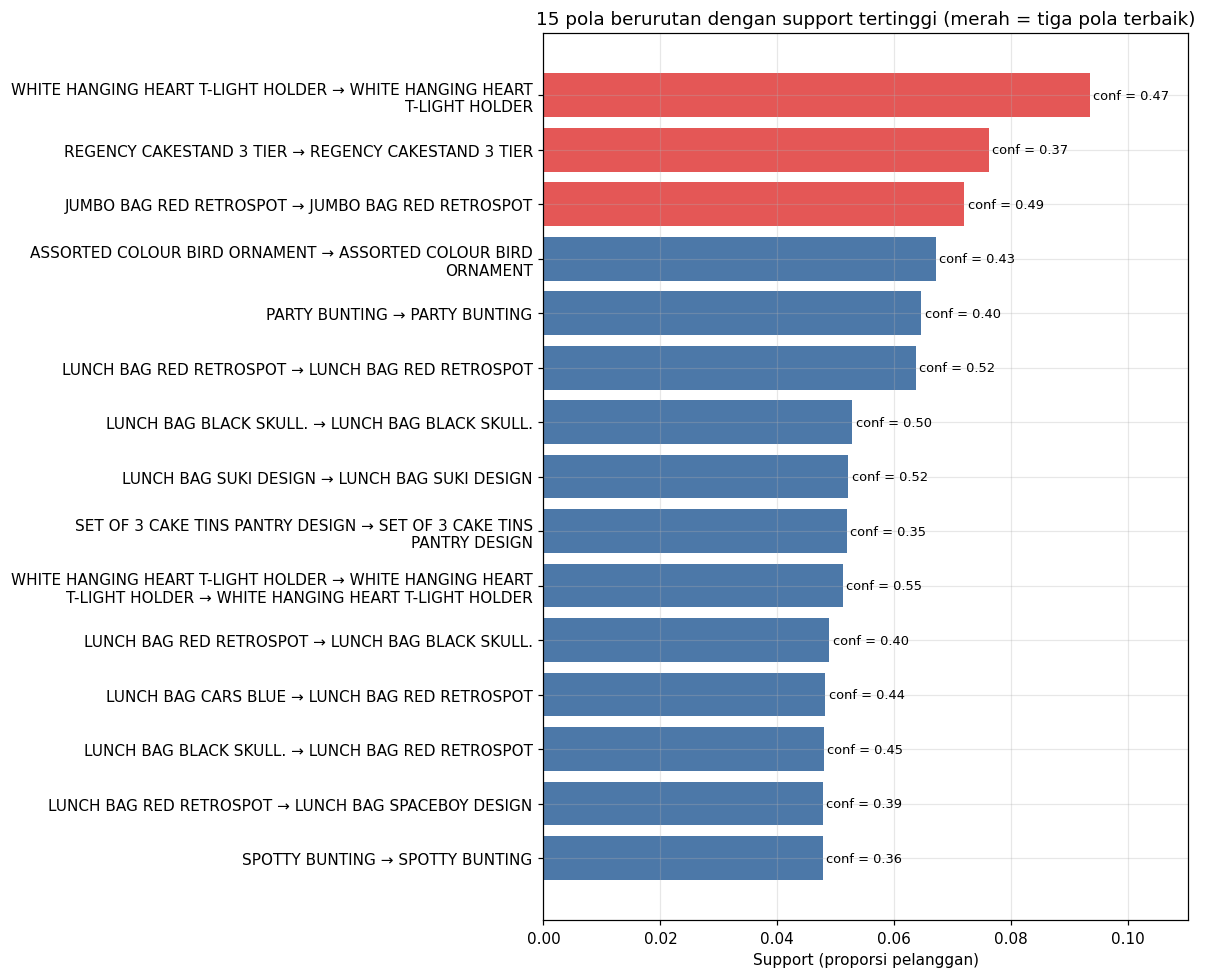

In [28]:
# Visualisasi: 15 pola berurutan dengan support tertinggi
top15 = hasil.head(15).iloc[::-1]
etiket = [textwrap.fill(t, 58) for t in top15["Pola Berurutan"]]

fig, ax = plt.subplots(figsize=(11, 9))
bars = ax.barh(etiket, top15["Support"], color=["#E45756" if i >= 12 else "#4C78A8" for i in range(15)])
for b, conf in zip(bars, top15["Confidence"]):
    ax.text(b.get_width() + 0.0006, b.get_y() + b.get_height() / 2, f"conf = {conf:.2f}", va="center", fontsize=8.5)
ax.set_xlabel("Support (proporsi pelanggan)")
ax.set_title("15 pola berurutan dengan support tertinggi (merah = tiga pola terbaik)")
ax.set_xlim(0, top15["Support"].max() * 1.18)
plt.tight_layout()
plt.show()

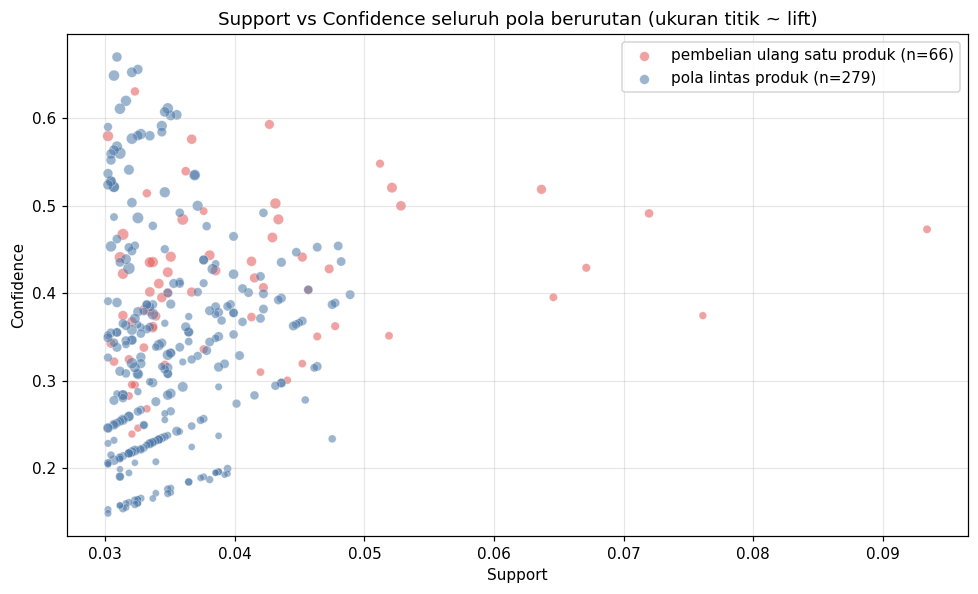

In [29]:
# Hubungan support, confidence, dan lift seluruh pola berurutan
fig, ax = plt.subplots(figsize=(9, 5.5))
for flag, warna, nama in [(True, "#E45756", "pembelian ulang satu produk"), (False, "#4C78A8", "pola lintas produk")]:
    sub = hasil[hasil["Pembelian Ulang"] == flag]
    ax.scatter(sub["Support"], sub["Confidence"], s=14 + 6 * sub["Lift"].clip(upper=20),
               alpha=0.55, color=warna, label=f"{nama} (n={len(sub)})", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Support")
ax.set_ylabel("Confidence")
ax.set_title("Support vs Confidence seluruh pola berurutan (ukuran titik ~ lift)")
ax.legend()
plt.tight_layout()
plt.show()

### 5.3 Pola lintas produk (analisis tambahan)

Tiga pola dengan support tertinggi seluruhnya berupa pembelian ulang produk yang sama. Itu wajar, karena produk terlaris punya peluang terbesar dibeli lagi. Untuk melihat pola yang lebih informatif secara bisnis, berikut pola yang **menghubungkan dua produk atau lebih yang berbeda**, diurutkan menurut support, lalu menurut lift.

In [30]:
lintas = hasil[~hasil["Pembelian Ulang"]]
kolom = ["Pola Berurutan", "Support Count", "Support", "Confidence", "Lift"]

print("10 pola lintas produk dengan SUPPORT tertinggi")
display(lintas[kolom].head(10).round({"Support": 4, "Confidence": 4, "Lift": 2}))

print("10 pola lintas produk dengan LIFT tertinggi")
display(lintas.sort_values(["Lift", "Support"], ascending=False)[kolom].head(10).round({"Support": 4, "Confidence": 4, "Lift": 2}))

10 pola lintas produk dengan SUPPORT tertinggi


,Pola Berurutan,Support Count,Support,Confidence,Lift
Peringkat,,,,,
11,LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.,212,0.0489,0.3985,3.77
12,LUNCH BAG CARS BLUE → LUNCH BAG RED RETROSPOT,209,0.0482,0.4363,3.56
13,LUNCH BAG BLACK SKULL. → LUNCH BAG RED RETROSPOT,208,0.0480,0.4541,3.70
14,LUNCH BAG RED RETROSPOT → LUNCH BAG SPACEBOY DESIGN,207,0.0477,0.3891,3.44
16,LUNCH BAG RED RETROSPOT → LUNCH BAG SUKI DESIGN,206,0.0475,0.3872,3.87
17,REGENCY CAKESTAND 3 TIER → SET OF 3 REGENCY CAKE TINS,206,0.0475,0.2338,2.15
19,LUNCH BAG PINK POLKADOT → LUNCH BAG RED RETROSPOT,201,0.0464,0.4527,3.69
21,JUMBO BAG RED RETROSPOT → JUMBO BAG VINTAGE DOILY,201,0.0464,0.3165,3.78
22,JUMBO BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,200,0.0461,0.3150,2.57


10 pola lintas produk dengan LIFT tertinggi


,Pola Berurutan,Support Count,Support,Confidence,Lift
Peringkat,,,,,
258,"ALARM CLOCK BAKELIKE GREEN → {ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE RED}",138,0.0318,0.4286,7.71
288,"{ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE RED} → ALARM CLOCK BAKELIKE GREEN",135,0.0311,0.5602,7.54
181,"ALARM CLOCK BAKELIKE RED → {ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE RED}",146,0.0337,0.3763,6.77
221,LUNCH BAG DOILEY PATTERN → LUNCH BAG VINTAGE DOILY,141,0.0325,0.4862,6.61
244,"{ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE RED} → ALARM CLOCK BAKELIKE RED",139,0.0321,0.5768,6.45
106,JUMBO BAG DOILEY PATTERNS → JUMBO BAG VINTAGE DOILY,160,0.0369,0.5351,6.39
251,"LUNCH BAG SUKI DESIGN → {LUNCH BAG BLACK SKULL., LUNCH BAG SUKI DESIGN}",139,0.0321,0.3203,6.28
310,"{LUNCH BAG BLACK SKULL., LUNCH BAG CARS BLUE} → LUNCH BAG BLACK SKULL.",133,0.0307,0.6488,6.14
326,ALARM CLOCK BAKELIKE PINK → ALARM CLOCK BAKELIKE GREEN,132,0.0304,0.4536,6.11


**Pola lintas produk menunjukkan dua hal.**

1. **Pola dalam satu "keluarga" produk.** Daftar support tertinggi didominasi varian produk yang sama, misalnya `LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.` atau `JUMBO BAG RED RETROSPOT → JUMBO BAG VINTAGE DOILY`. Daftar lift tertinggi didominasi `ALARM CLOCK BAKELIKE` berbagai warna: pola `ALARM CLOCK BAKELIKE GREEN → {ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE RED}` memiliki lift sekitar 7,7. Artinya pelanggan cenderung **melengkapi koleksi warna atau desain** pada pembelian berikutnya.
2. **Pola pelengkap antar-keluarga produk.** Contohnya `REGENCY CAKESTAND 3 TIER → SET OF 3 REGENCY CAKE TINS` (support 0,0475, confidence 0,2338, lift 2,15) dan `JUMBO BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT` (confidence 0,3150, lift 2,57). Produk-produk ini berbagi tema desain yang sama (*Regency*, *Retrospot*), sehingga cocok untuk **paket bundling** atau rekomendasi "pelanggan yang membeli X biasanya membeli Y berikutnya".

---

## 6. Laporan

### 6.1 Hasil eksplorasi dan pembersihan data

Dataset Online Retail memuat 541.909 baris dan 8 kolom. Dua kolom penting memiliki nilai kosong: `Description` (1.454 baris, 0,27%) dan `CustomerID` (135.080 baris, 24,93%). Selain itu terdapat 9.288 baris transaksi dibatalkan dan 10.624 baris dengan `Quantity` nol atau negatif.

| Tahap | Baris | Invoice | Pelanggan |
|---|---:|---:|---:|
| Sebelum pembersihan | 541.909 | 25.900 | 4.372 |
| Sesudah pembersihan sesuai ketentuan (Description kosong, transaksi dibatalkan, Quantity ≤ 0, CustomerID kosong) | 397.924 | 18.536 | 4.339 |
| Sesudah langkah tambahan (buang biaya non-produk POST, M, DOT) | 396.519 | 18.419 | 4.336 |

Langkah tambahan dilakukan karena baris `POSTAGE`, `MANUAL`, dan `DOTCOM POSTAGE` adalah biaya layanan, bukan produk; jika dibiarkan, baris tersebut dapat memunculkan pola yang tidak bermakna bagi analisis produk. Total baris yang dibuang adalah 26,8% dari data awal.

Data bersih membentuk **4.336 sequence** (satu per pelanggan) dengan total 18.419 itemset (invoice) dan 3.855 produk unik. Rata-rata pelanggan memiliki 4,25 invoice (median 2). Sebanyak 1.506 pelanggan (34,7%) hanya memiliki satu invoice sehingga tidak dapat membentuk pola berurutan, sedangkan 2.830 pelanggan (65,3%) memiliki dua invoice atau lebih.

### 6.2 Pola berurutan dan analisis evaluasi

- **Algoritma**: PrefixSpan *itemset-aware* (implementasi sendiri, divalidasi dengan brute force pada contoh kecil dan menghasilkan pola yang identik).
- **Minimum support**: titik awal 0.01 menghasilkan pola terlalu banyak (22.814 pola, bahkan dengan panjang dibatasi 2 item), sedangkan 0.05 terlalu sedikit (hanya 10 pola berurutan). Dipilih **0.03** (≥ 131 pelanggan).
- **Hasil**: 1.277 pola frequent, dengan **345 pola berurutan** (334 pola dengan 2 itemset, 10 pola dengan 3 itemset, 1 pola dengan 4 itemset). Dari 345 pola tersebut, 66 adalah pembelian ulang satu produk dan 279 adalah pola lintas produk.
- **Tiga pola terbaik (support tertinggi)**:

| # | Pola | Support | Confidence | Lift |
|---|---|---:|---:|---:|
| 1 | WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER | 0,0934 | 0,4731 | 2,40 |
| 2 | REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER | 0,0761 | 0,3746 | 1,84 |
| 3 | JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT | 0,0720 | 0,4913 | 3,36 |

### 6.3 Kesimpulan

1. **Pembelian ulang adalah pola berurutan yang paling dominan.** Tiga pola dengan support tertinggi, bahkan sepuluh teratas, seluruhnya berupa pembelian ulang produk yang sama. Pelanggan toko ini cenderung kembali membeli produk yang sama; 37% sampai 49% pembeli produk terlaris membelinya lagi di invoice berikutnya, dengan lift 1,8 sampai 3,4.
2. **Pola lintas produk terbentuk di dalam keluarga produk.** Pelanggan sering membeli varian lain (warna atau desain) dari produk yang sama atau berseri, seperti `LUNCH BAG`, `JUMBO BAG`, dan `ALARM CLOCK BAKELIKE`. Lift tertinggi mencapai sekitar 7,7, yang berarti peluang munculnya varian berikutnya jauh di atas peluang dasarnya.
3. **Ada pola pelengkap antar-keluarga produk** yang berbagi tema desain, misalnya `REGENCY CAKESTAND 3 TIER → SET OF 3 REGENCY CAKE TINS`. Pola ini berguna untuk bundling dan rekomendasi pembelian berikutnya.
4. **Pola berurutan di dataset ini umumnya pendek.** Dari 345 pola, 334 hanya melibatkan dua invoice. Pada `min_support = 0.03` hanya 11 pola yang melibatkan tiga invoice atau lebih, sehingga pola pembelian panjang jarang dimiliki banyak pelanggan sekaligus.
5. **Rekomendasi bisnis**: kirim pengingat atau penawaran *restock* setelah pembelian pertama produk dengan tingkat pembelian ulang tinggi, jaga ketersediaan stok produk tersebut, dan tawarkan varian atau produk bertema sama pada pembelian berikutnya.

### 6.4 Keterbatasan

- Support dihitung terhadap **seluruh** pelanggan, termasuk 34,7% pelanggan yang hanya memiliki satu invoice. Support menjadi lebih rendah dibanding jika dihitung hanya pada pelanggan dengan dua invoice atau lebih.
- Pola yang ditemukan tidak mempertimbangkan **jarak waktu** antar-invoice (tidak ada *gap constraint*), sehingga pembelian ulang dalam sebulan dan dalam setahun diperlakukan sama.
- Item didefinisikan pada level `Description`, sehingga varian warna atau desain dihitung sebagai produk berbeda. Analisis pada level kategori (*multilevel*, materi 5.1.1) berpotensi menghasilkan pola yang lebih ringkas.
- Banyak pelanggan dataset ini diduga pembeli grosir atau reseller, sehingga pola pembelian ulang mungkin tidak mewakili pelanggan ritel biasa.
- Dataset hanya mencakup satu toko di Inggris pada Desember 2010 sampai Desember 2011, sehingga hasil tidak otomatis berlaku untuk toko atau periode lain.